In [5]:
%pip install numpy pandas matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.7 MB 379.0 kB/s eta 0:00:27
   - -------------------------------------- 0.5/10.7 MB 379.0 kB/s eta 0:00:27
   - -------------------------------------- 0.5/10.7 MB 379.0 kB/s eta 0:00:27
   - -------------------------------------- 0.5/10.7 MB 379.0 kB/s eta 0:00:27
   -- ------------------------------------- 0.8/10.7 MB 380.5 kB/s eta 0:00:27
   -- ------------------------------------- 0.8/10.7 MB 380.5 kB/s eta 0:00:27
   -- ------------------------------------- 0.8/10.7 MB 380.5 kB/s eta 0:00:27
   -- --------------------

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

In [10]:
data = pd.read_csv(url)
print(data.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [11]:
print(data.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [13]:
print(data.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [15]:
#fill missing ages and assign back to dataframe
data['Age']=data['Age'].fillna(data['Age'].median())

In [17]:
#fill missing 'Embarked' values with the mode
data['Embarked']=data['Embarked'].fillna(data['Embarked'].mode()[0])

In [19]:
#check missing values after filling
print("Missing values after filling")
print(data.isnull().sum())

Missing values after filling
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64


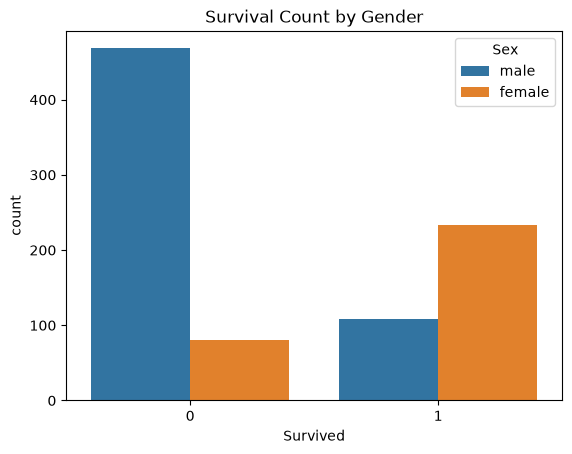

In [20]:
import seaborn as sns
sns.countplot(data=data, x ="Survived", hue='Sex')
plt.title('Survival Count by Gender')
plt.show()

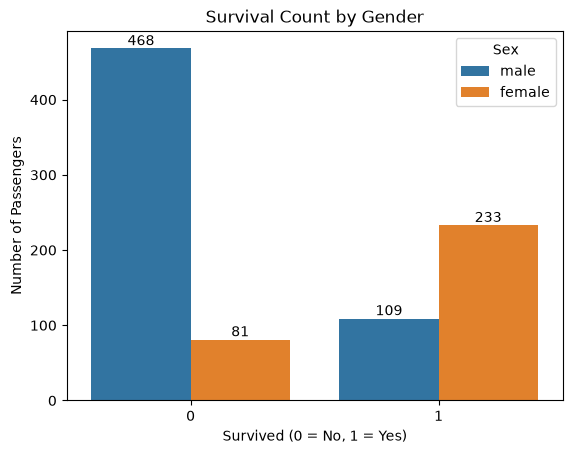

In [24]:
ax = sns.countplot(
    data=data,
    x="Survived",
    hue="Sex"
)

ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])

plt.title("Survival Count by Gender")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

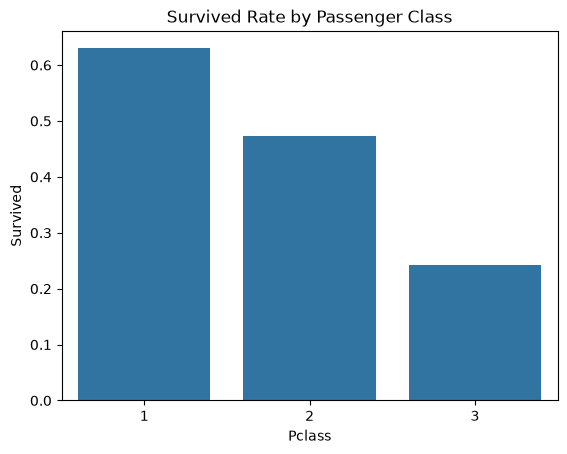

In [27]:
# Visualizing survival rate by passenger class
sns.barplot(data=data, x='Pclass', y='Survived', errorbar=None)
plt.title("Survived Rate by Passenger Class")
plt.show()

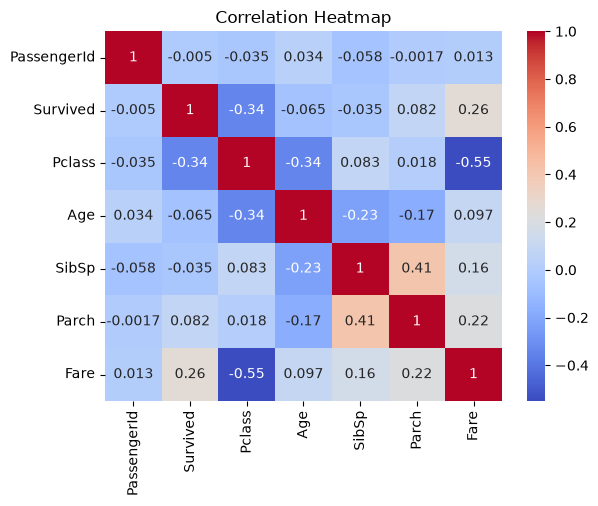

In [28]:
# caculate the correlation matrix only for numeric colums
correlation = data.select_dtypes(include='number').corr()

#plotting the heatmap
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

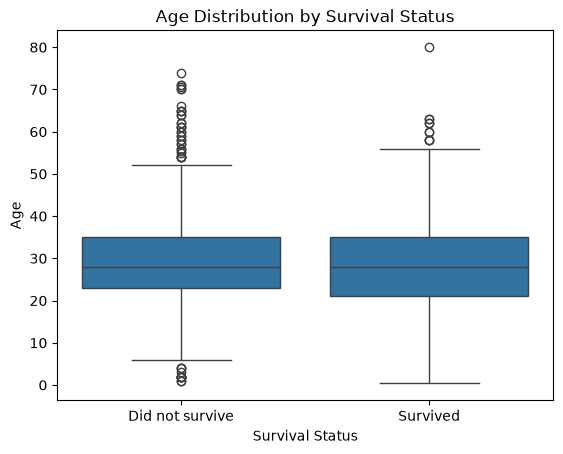

In [29]:
#visualizing age distribution by survival status
sns.boxplot(data=data, x='Survived', y='Age')
plt.title('Age Distribution by Survival Status')
plt.xticks(ticks=[0,1], labels=['Did not survive', 'Survived'])
plt.ylabel('Age')
plt.xlabel('Survival Status')
plt.show()